<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 26 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   annual_inc       800 non-null    float64
 1   dti              800 non-null    float64
 2   delinq_2yrs      800 non-null    int64  
 3   fico_range_low   800 non-null    int64  
 4   revol_util       799 non-null    float64
 5   total_rec_prncp  800 non-null    float64
 6   10+ years        800 non-null    bool   
 7   2 years          800 non-null    bool   
 8   3 years          800 non-null    bool   
 9   4 years          800 non-null    bool   
 10  5 years          800 non-null    bool   
 11  6 years          800 non-null    bool   
 12  7 years          800 non-null    bool   
 13  8 years          800 non-null    bool   
 14  9 years          800 non-null    bool   
 15  < 1 year         800 non-null    bool   
 16  NONE             800 non-null    bool   
 17  OTHER            800 non-nu

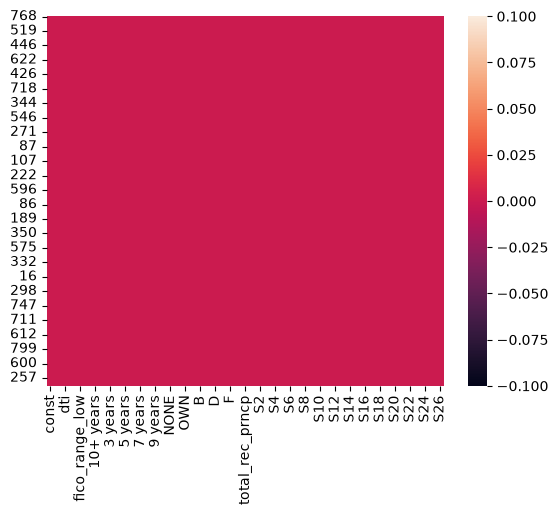

In [1]:
# -*- coding: utf-8 -*-
"""
Created on Sat Sep 19 15:17:45 2026

@author: Dell
"""

import numpy as np
import os
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
pd.set_option('display.max_column',None)

file_p='C:\\Users\\Dell\\My Drive\\data\\Lending Club data Python red 2.xlsx'
d1=pd.read_excel(file_p)
os.chdir("C:\\Users\\Dell\\My Drive\\data")
e_length=pd.get_dummies(d1['emp_length'],drop_first=True)
HO=pd.get_dummies(d1['home_ownership'], drop_first=True)
grade=pd.get_dummies(d1['grade'],drop_first=True)
d1.drop(['id','member_id','loan_amnt','funded_amnt','funded_amnt_inv','term','int_rate','installment','grade','sub_grade','emp_name','emp_length','home_ownership','is_inc_v','accept_d','exp_d','list_d','issue_d','loan_status','pymnt_plan','url','desc','purpose','title','addr_city','addr_state','acc_now_delinq','acc_open_past_24mths','bc_open_to_buy','percent_bc_gt_75','bc_util','delinq_amnt','earliest_cr_line','fico_range_high','inq_last_6mths','mths_since_last_delinq','mths_since_last_record','mths_since_recent_inq','mths_since_recent_loan_delinq','mths_since_recent_revol_delinq','mths_since_recent_bc','mort_acc','open_acc','pub_rec_gt_100','pub_rec','total_bal_ex_mort','revol_bal','total_bc_limit','total_acc','initial_list_status','out_prncp','out_prncp_inv','total_pymnt','total_pymnt_inv','total_rec_int','total_rec_late_fee','last_pymnt_d','last_pymnt_amnt','next_pymnt_d','last_credit_pull_d','last_fico_range_high','last_fico_range_low'],axis=1,inplace=True)
d1=pd.concat([d1,e_length,HO,grade],axis=1)
d1.info()

d1 = d1.dropna(subset=['revol_util'])
dep=pd.DataFrame(d1['total_rec_prncp'])
d1=d1.drop(['total_rec_prncp'],axis=1)
d1=d1.apply(pd.to_numeric)
dep=dep.apply(pd.to_numeric)
X_train,X_test,y_train, y_test=train_test_split(d1,dep,test_size=0.2,random_state=36)
d2=pd.concat([X_train,y_train[['total_rec_prncp']]],axis=1)
d2.info()

col_list=d2.columns[5:25].tolist()
d2[col_list]=d2[col_list].astype(int) #change TRUE/FALSE to 0/1
d2=sm.add_constant(d2)
d2.info()

col_names=d2.columns[1:27].tolist()
r1=[(j,index) for (j,index) in enumerate(col_names)]
print(r1)
#Now standardize the values
#len(col_names)=26

for i in range(len(col_names)):
    c_n='S'+str(i+1) #i runs from 0 to 25
    d2[c_n]=(d2[r1[i][1]]-d2[r1[i][1]].mean())/d2[r1[i][1]].std()
d2.info()
sns.heatmap(d2.isnull())
#d2.to_csv('Lending_Club_chk_data_std.csv')

#extract the const and the standardised values (S1 to S26) in new df d_x2
d_x2=pd.concat([d2.iloc[:,0:1], d2.iloc[:,27:53]],axis=1)
d_x2.info()
#d_x2.to_csv('Lending club chk constant and std.csv')
# change here

def RS1(d1, B0):
    col_names2=d1.columns.tolist()
    m1=len(col_names2)-1 #m1=26
    #print("m1:",m1)
    r2=[(j,index) for (j,index) in enumerate(col_names2)]
    l1=len(B0) #l1=26
    t1=0.0
    l2=len(d1) #l2=639
    for i in range(l2):
        t2=0.0
        for j in range(l1): 
            #l1=26
            t2=t2+(B0[j]*d1.iloc[i][r2[j][1]])
        t3=(t2-d1.iloc[i][r2[m1][1]])**2
        t1=t1+t3
    t1=0.5*t1
    return t1
def UP_TH(d1, B0):
    n1=len(d1) #n1=639
    col_names3=d1.columns.tolist()
    #print(len(col_names3))
    r3=[(j,index) for (j,index) in enumerate(col_names3)]
    m1=len(col_names3)-1 #m1=26
    #print("m1:",m1)
    n2=len(B0) #n2=26
    S1=[]
    for i in range(n2): 
        #i runs from 0 to 25
        t2=0.0
        for j in range(n1):
            #n1 runs from 0 to 638
            t3=0.0
            for k in range(n2):
                # k runs from 0 to 25
                t3=t3+(B0[k]*d1.iloc[j][r3[k][1]])
            t4=(t3-d1.iloc[j][r3[m1][1]])*d1.iloc[j][r3[i][1]]
            t2=t2+t4
        b1=B0[i]-0.001*t2
        S1.append(b1)
    return S1
         
    
l2=d_x2.columns[0:26].tolist()
l3=len(l2) #l3 is the length of the initial th vector len(l2)=26
KL=[]
TH0=[0]*26
TH_X=np.zeros((l3))
k1=RS1(d_x2,TH0)
KL.append(k1)
iter=0
chk1=0.5
while(iter<10000 and chk1>0.005):
    TH_X=UP_TH(d_x2,TH0)
    k2=RS1(d_x2,TH_X)
    chk1=abs(k2-k1)
    KL.append(k2)
    TH0=TH_X
    k1=k2
    iter=iter+1
for j in range(len(TH_X)):
    print(f"Coefficient {j+1}: {TH_X[j]:.6f}")
#X_test.to_csv('Lending Club_X_test.csv')
#y_test.to_csv('Lending Club_y_test.csv')
#df = pd.DataFrame(TH_X, columns=['TH'])
#df.to_csv('Lending_CLub_Theta.csv')
    
    
    
